**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [66]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [67]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [68]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [70]:
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [71]:
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


Вивести типи даних

In [72]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [73]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [74]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [75]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [76]:
df.drop_duplicates(inplace=True)

In [77]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [78]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


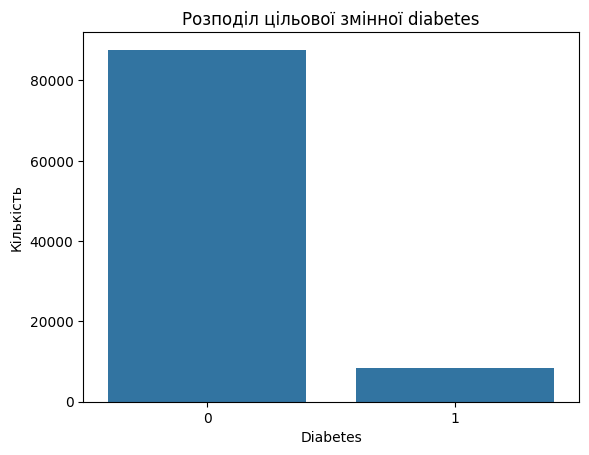

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='diabetes', data=df)

plt.title('Розподіл цільової змінної diabetes')
plt.xlabel('Diabetes')
plt.ylabel('Кількість')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [80]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [81]:
from sklearn.model_selection import train_test_split

X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (76916, 8)
X_test: (19230, 8)
y_train: (76916,)
y_test: (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [82]:
X_train = pd.get_dummies(
    X_train,
    columns=['gender', 'smoking_history']
)

X_test = pd.get_dummies(
    X_test,
    columns=['gender', 'smoking_history']
)

In [83]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [84]:
correlation_with_target = X_train.corrwith(y_train)

print(correlation_with_target.sort_values(ascending=False))

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
gender_Female                 -0.040533
smoking_history_No Info       -0.113053
dtype: float64


In [85]:
correlation_matrix = X_train.corr()

correlation_matrix

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
age,1.000000,0.259009,0.238917,0.347008,0.105375,0.114959,0.027462,-0.027221,-0.008864,-0.291283,0.031472,0.067723,0.223120,0.066046,0.071176
hypertension,0.259009,1.000000,0.122113,0.149846,0.080517,0.085594,-0.013277,0.013385,-0.003925,-0.111506,0.017765,0.020239,0.083925,0.041884,-0.005152
heart_disease,0.238917,0.122113,1.000000,0.064159,0.070383,0.068966,-0.079086,0.079167,-0.002785,-0.048904,0.004155,0.040498,0.096514,-0.034036,0.006647
bmi,0.347008,0.149846,0.064159,1.000000,0.084479,0.092277,0.022857,-0.022787,-0.002632,-0.229409,0.054103,0.045878,0.111746,0.089300,0.031744
HbA1c_level,0.105375,0.080517,0.070383,0.084479,1.000000,0.170634,-0.019049,0.019068,-0.000654,-0.043178,0.003570,0.008360,0.035302,0.010376,0.009405
blood_glucose_level,0.114959,0.085594,0.068966,0.092277,0.170634,1.000000,-0.017346,0.017341,0.000245,-0.049135,0.009744,0.003974,0.043716,0.011513,0.004766
gender_Female,0.027462,-0.013277,-0.079086,0.022857,-0.019049,-0.017346,1.000000,-0.999626,-0.015943,-0.054212,-0.024402,-0.011986,-0.047713,0.098419,0.008968
gender_Male,-0.027221,0.013385,0.079167,-0.022787,0.019068,0.017341,-0.999626,1.000000,-0.011415,0.054203,0.024523,0.012063,0.047837,-0.098259,-0.009612
gender_Other,-0.008864,-0.003925,-0.002785,-0.002632,-0.000654,0.000245,-0.015943,-0.011415,1.000000,0.000430,-0.004385,-0.002796,-0.004427,-0.006046,0.023495
smoking_history_No Info,-0.291283,-0.111506,-0.048904,-0.229409,-0.043178,-0.049135,-0.054212,0.054203,0.000430,1.000000,-0.234333,-0.149406,-0.236566,-0.537979,-0.192292


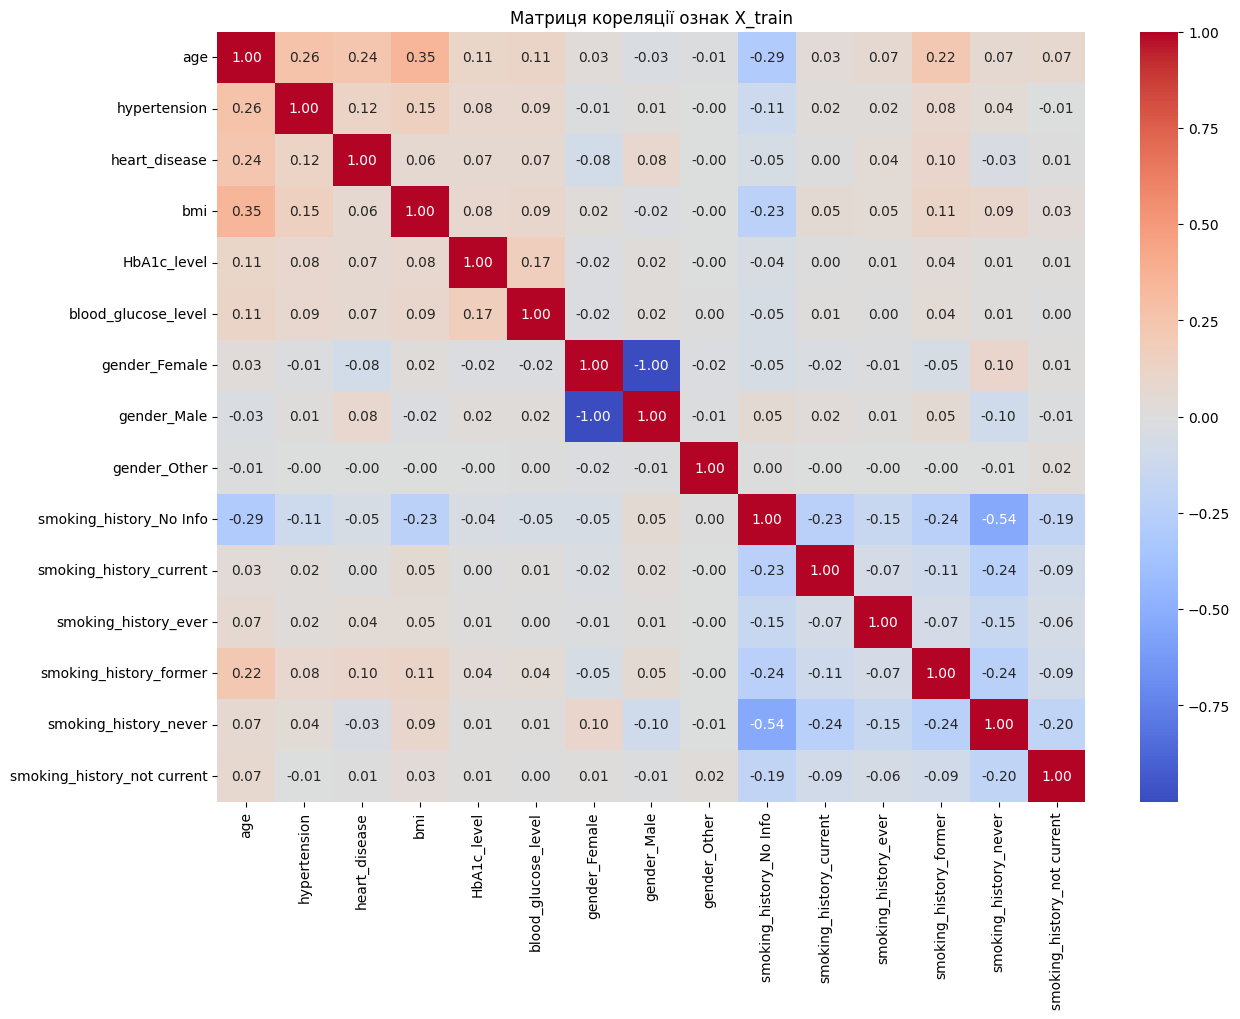

In [86]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Матриця кореляції ознак X_train')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

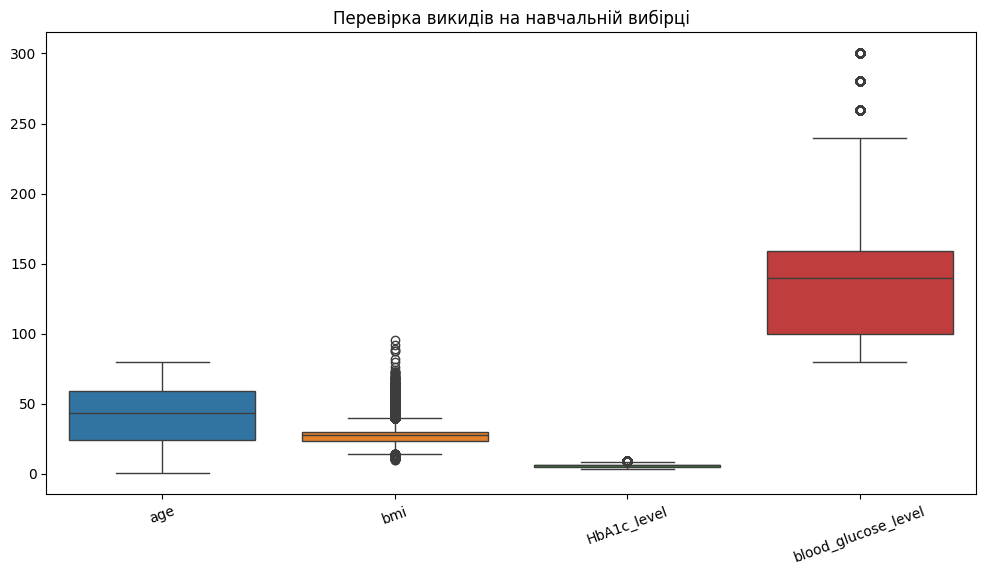

In [87]:
continuous_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_train[continuous_cols])

plt.title('Перевірка викидів на навчальній вибірці')
plt.xticks(rotation=20)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [88]:
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

IQR: 6.460000000000001
Нижня межа: 13.7
Верхня межа: 39.540000000000006


Перевірити асиметрію розподілів ознак **на train**

In [89]:
print("Асиметрія розподілів:")
print(X_train[continuous_cols].skew())

Асиметрія розподілів:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [90]:
print("Пропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never  

**Проміжний висновок:У процесі аналізу навчальної вибірки було перевірено баланс класів цільової змінної diabetes, кореляцію між ознаками, наявність викидів та асиметрію розподілів.

Кореляційний аналіз дозволяє визначити, які ознаки мають найбільший зв'язок із цільовою змінною, а також виявити ознаки з високою взаємною кореляцією. Автоматично видаляти ознаки за результатами цього аналізу не потрібно.

За допомогою boxplot було перевірено наявність викидів у віці, індексі маси тіла, рівні HbA1c та глюкози в крові. Викиди в цій роботі не видаляються, оскільки екстремальні значення можуть мати клінічне значення.

Тестову вибірку не використовували для прийняття рішень щодо обробки даних.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [91]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [92]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Кількість класів до балансування:")
print(Counter(y_train))

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nКількість класів після балансування:")
print(Counter(y_train_smote))

Кількість класів до балансування:
Counter({0: 70130, 1: 6786})

Кількість класів після балансування:
Counter({0: 70130, 1: 70130})


Оголошуємо моделі

In [93]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        random_state=42,
        max_iter=1000
    ),

    "Ridge Classifier": RidgeClassifier(),

    "SGD Classifier": SGDClassifier(
        random_state=42,
        max_iter=1000
    ),

    "SVC": SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



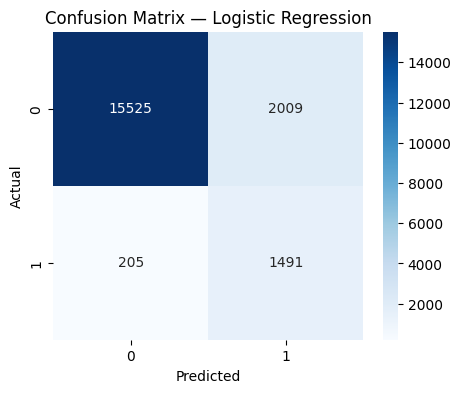


Модель: Ridge Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



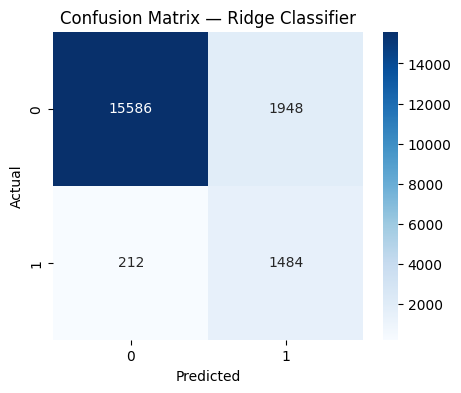


Модель: SGD Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



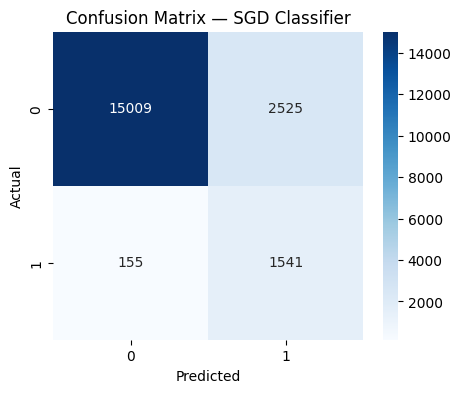


Модель: SVC

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



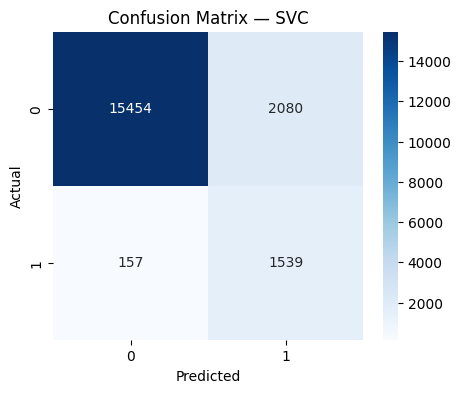

In [94]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

results = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Модель: {name}")
    print('='*50)

    # Навчання
    model.fit(X_train_smote, y_train_smote)

    # Прогноз
    y_pred = model.predict(X_test_scaled)

    # Звіт
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Матриця плутанини
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    results[name] = {
        "model": model,
        "precision": classification_report(
            y_test, y_pred, output_dict=True
        )["1"]["precision"],
        "recall": classification_report(
            y_test, y_pred, output_dict=True
        )["1"]["recall"],
        "f1": classification_report(
            y_test, y_pred, output_dict=True
        )["1"]["f1-score"]
    }

Оптимізувати гіперпараметри


In [95]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

print("Усі необхідні бібліотеки імпортовано!")

Усі необхідні бібліотеки імпортовано!


In [96]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1]
    },

    "Ridge Classifier": {
        "model__alpha": [1, 10]
    },

    "SGD Classifier": {
        "model__loss": ["hinge", "log_loss"],
        "model__alpha": [0.0001, 0.001]
    },

    "SVC": {
        "model__C": [0.1, 1],
        "model__kernel": ["linear"]
    }
}

In [97]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Оптимізація моделі: {name}")
    print('='*60)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    grid_search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=1000,
        factor=3,
        n_jobs=-1,
        verbose=2
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    best_scores[name] = grid_search.best_score_

    print("\nНайкращі параметри:")
    print(grid_search.best_params_)

    print("\nСередній F1:")
    print(grid_search.best_score_)

    y_pred = grid_search.best_estimator_.predict(X_test)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))


Оптимізація моделі: Logistic Regression
n_iterations: 1
n_required_iterations: 1
n_possible_iterations: 4
min_resources_: 1000
max_resources_: 76916
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 2
n_resources: 1000
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Найкращі параметри:
{'model__C': 0.1}

Середній F1:
0.6707704335998371

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


Оптимізація моделі: Ridge Classifier
n_iterations: 1
n_required_iterations: 1
n_possible_iterations: 4
min_resources_: 1000
max_resources_: 76916
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 2
n_resources: 1000
Fitting 3 folds for each of 2 candi

In [98]:
print(X_train.shape)

(76916, 15)


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [99]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [100]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__solver": ["liblinear", "lbfgs"]
    },

    "Ridge Classifier": {
        "model__alpha": [0.1, 1, 10, 100]
    },

    "SGD Classifier": {
        "model__loss": ["hinge", "log_loss"],
        "model__penalty": ["l2", "l1", "elasticnet"],
        "model__alpha": [0.0001, 0.001, 0.01]
    },

    "SVC": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

print("param_grids успішно створено")

param_grids успішно створено


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [101]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nОптимізація: {name}")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    grid_search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=300,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    best_scores[name] = grid_search.best_score_

    print("Найкращі параметри:", grid_search.best_params_)
    print("F1:", grid_search.best_score_)


Оптимізація: Logistic Regression
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 6
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 6
n_resources: 300
Fitting 3 folds for each of 6 candidates, totalling 18 fits
----------
iter: 1
n_candidates: 2
n_resources: 900
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Найкращі параметри: {'model__C': 10, 'model__solver': 'lbfgs'}
F1: 0.530594813683049

Оптимізація: Ridge Classifier
n_iterations: 2
n_required_iterations: 2
n_possible_iterations: 6
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 4
n_resources: 300
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 1
n_candidates: 2
n_resources: 900
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Найкращі параметри: {'model__alpha': 10}
F1: 0.5333333333333333

Оптимізація: SGD Classifier
n_iterations: 3

In [102]:
# Вибираємо модель із найкращим F1 на кросвалідації
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print("Середній F1:", best_scores[best_model_name])

Найкраща модель: SVC
Середній F1: 0.5862417527128858


In [103]:
import pandas as pd
import numpy as np

np.random.seed(42)

random_indices = np.random.choice(
    len(X_test),
    size=10,
    replace=False
)

y_pred_best = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Індекс": random_indices,
    "Істинний клас": np.array(y_test)[random_indices],
    "Передбачений клас": y_pred_best[random_indices]
})

print(comparison)

   Індекс  Істинний клас  Передбачений клас
0     341              0                  0
1    8171              0                  0
2   13626              0                  1
3    6178              0                  0
4   14765              0                  0
5    2641              0                  0
6   16024              0                  0
7   16466              0                  0
8    2995              0                  1
9    1512              0                  0


Підсумкові висновки
1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів на train?

У початковому датасеті спостерігався значний дисбаланс класів: 87 664 об'єкти (91,18%) належали до класу diabetes = 0, а 8 482 об'єкти (8,82%) — до класу diabetes = 1. Таким чином, кількість негативних випадків значно перевищувала кількість позитивних. Для усунення дисбалансу було застосовано метод SMOTE лише до навчальної вибірки. Після балансування кількість об'єктів обох класів становила по 70 130.

Кореляційний аналіз використовувався для оцінювання взаємозв'язків між ознаками та цільовою змінною. Перевірка викидів проводилася на навчальних даних для виявлення аномальних значень. Числових результатів кореляції та перевірки викидів у наданих результатах немає, тому конкретні висновки щодо них не можна достовірно зазначити.

2. Які моделі дали кращі F1 і Recall для класу diabetes = 1? Яка модель обрана за крос-валідацією?

Під час початкового порівняння моделей найкращий Recall для класу diabetes = 1 показали SGD Classifier та SVC — 0,91. Найкращий F1-score до оптимізації продемонстрували Ridge Classifier та SVC — 0,58.

Після оптимізації гіперпараметрів найкращий результат крос-валідації отримала модель SGD Classifier із середнім F1-score 0,5915. Тому саме її було обрано як найкращу модель.

На тестовій вибірці оптимізована модель SGD Classifier показала Accuracy 0,8867, F1-score для класу 1 — 0,5781 та Recall — 0,88.

3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?

У результаті оптимізації було отримано такі найкращі гіперпараметри:
- Logistic Regression: C = 10, max_iter = 1000.
- Ridge Classifier: alpha = 10.
- SGD Classifier: alpha = 0.01, loss = 'log_loss', penalty = 'elasticnet', random_state = 42.
- SVC: C = 0.1, kernel = 'linear'.
Для найкращої моделі SGD Classifier матриця плутанини мала вигляд:
	Передбачено 0	Передбачено 1
Реально 0	15 560	1 974
Реально 1	204	1 492

Модель правильно визначила 15 560 випадків відсутності діабету та 1 492 випадки його наявності. Водночас було допущено 1 974 хибнопозитивні прогнози та 204 хибнонегативні прогнози. Це означає, що модель досить добре виявляє випадки діабету, проте іноді помилково класифікує здорових людей як хворих.

4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Тестову вибірку необхідно відкладати окремо, щоб об'єктивно оцінити якість моделі на даних, які вона не використовувала під час навчання. Це дозволяє уникнути витоку даних та отримати реалістичнішу оцінку здатності моделі працювати з новими прикладами.

Масштабування виконується шляхом навчання StandardScaler тільки на навчальній вибірці. Після цього отримані параметри масштабування застосовуються до тестової вибірки за допомогою методу transform.

Метод SMOTE також застосовується виключно до навчальних даних, оскільки його використання на тестовій вибірці штучно змінювало б розподіл класів та спотворювало результати оцінювання.

Таким чином, правильне розділення даних, масштабування та балансування дозволяють уникнути витоку інформації, забезпечити коректне навчання моделей і отримати об'єктивні результати їх тестування.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [104]:
!pip install -q xgboost lightgbm catboost

In [105]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import classification_report, confusion_matrix

In [106]:
class_counts = y_train.value_counts()

scale_pos_weight = class_counts[0] / class_counts[1]

extra_models = {
    'XGBoost': XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1
    ),

    'LightGBM': LGBMClassifier(
        random_state=42,
        class_weight='balanced',
        verbosity=-1,
        n_jobs=-1
    ),

    'CatBoost': CatBoostClassifier(
        random_seed=42,
        auto_class_weights='Balanced',
        verbose=0
    )
}

XGBoost

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.92      0.95     17534
           1       0.51      0.88      0.64      1696

    accuracy                           0.91     19230
   macro avg       0.75      0.90      0.80     19230
weighted avg       0.94      0.91      0.92     19230



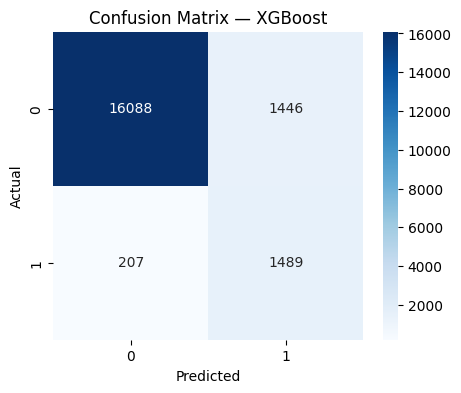

LightGBM

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.90      0.95     17534
           1       0.48      0.90      0.63      1696

    accuracy                           0.90     19230
   macro avg       0.73      0.90      0.79     19230
weighted avg       0.94      0.90      0.92     19230



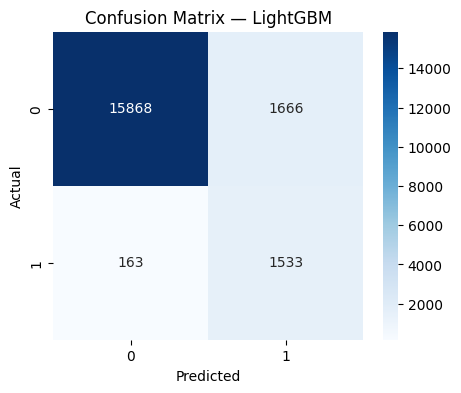

CatBoost

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.92      0.95     17534
           1       0.51      0.88      0.65      1696

    accuracy                           0.92     19230
   macro avg       0.75      0.90      0.80     19230
weighted avg       0.95      0.92      0.93     19230



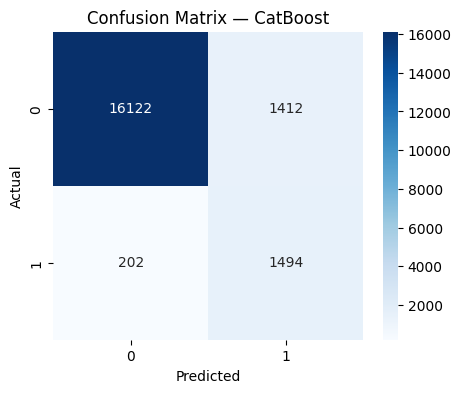

In [107]:
extra_results = {}

for name, model in extra_models.items():

    print("=" * 60)
    print(name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    extra_results[name] = {
        'F1': report['1']['f1-score'],
        'Recall': report['1']['recall'],
        'Precision': report['1']['precision']
    }

In [108]:
from imblearn.over_sampling import SMOTE
import pandas as pd

print("КЛАСИ ДО SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\nКЛАСИ ПІСЛЯ SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

print("\nРОЗМІР ДАНИХ ПІСЛЯ SMOTE:")
print(X_train_resampled.shape)

КЛАСИ ДО SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

КЛАСИ ПІСЛЯ SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64

РОЗМІР ДАНИХ ПІСЛЯ SMOTE:
(140260, 15)


In [109]:
extra_results_df = pd.DataFrame(extra_results).T

extra_results_df = extra_results_df.sort_values(
    by='F1',
    ascending=False
)

extra_results_df

,F1,Recall,Precision
CatBoost,0.649283,0.880896,0.514109
XGBoost,0.643058,0.877948,0.507325
LightGBM,0.626353,0.903892,0.479212


In [110]:
print("РОЗМІР ДАТАСЕТУ:")
print(df.shape)

print("\nПЕРШІ 5 РЯДКІВ:")
display(df.head())

print("\nІНФОРМАЦІЯ ПРО СТОВПЦІ:")
df.info()

print("\nПРОПУЩЕНІ ЗНАЧЕННЯ:")
print(df.isnull().sum())

print("\nРОЗПОДІЛ КЛАСІВ:")
print(df["diabetes"].value_counts())

print("\nВІДСОТКОВИЙ РОЗПОДІЛ КЛАСІВ:")
print(df["diabetes"].value_counts(normalize=True) * 100)

РОЗМІР ДАТАСЕТУ:
(96146, 9)

ПЕРШІ 5 РЯДКІВ:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



ІНФОРМАЦІЯ ПРО СТОВПЦІ:
<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  object 
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  object 
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 7.3+ MB

ПРОПУЩЕНІ ЗНАЧЕННЯ:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64



In [111]:
print("РОЗМІРИ ВИБІРОК:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nКЛАСИ ДО SMOTE:")
print(y_train.value_counts())

print("\nКЛАСИ ПІСЛЯ SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

РОЗМІРИ ВИБІРОК:
X_train: (76916, 15)
X_test: (19230, 15)
y_train: (76916,)
y_test: (19230,)

КЛАСИ ДО SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

КЛАСИ ПІСЛЯ SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64



Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

Confusion Matrix:
[[15525  2009]
 [  205  1491]]


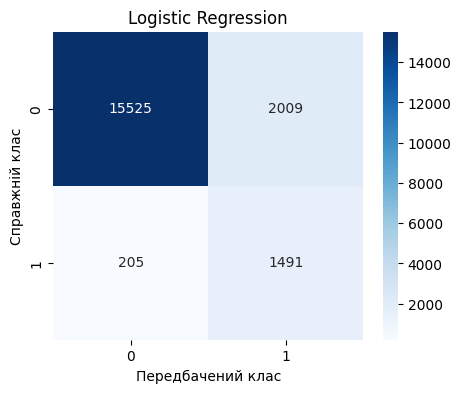


Ridge Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230

Confusion Matrix:
[[15586  1948]
 [  212  1484]]


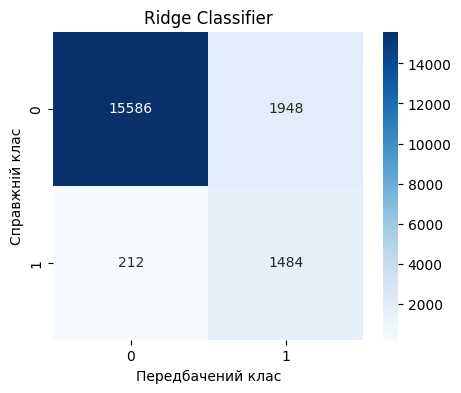


SGD Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230

Confusion Matrix:
[[15009  2525]
 [  155  1541]]


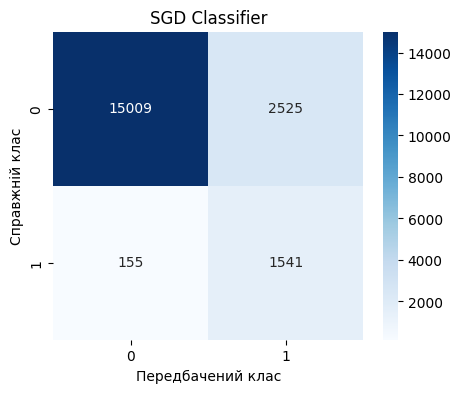


SVC

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230

Confusion Matrix:
[[15454  2080]
 [  157  1539]]


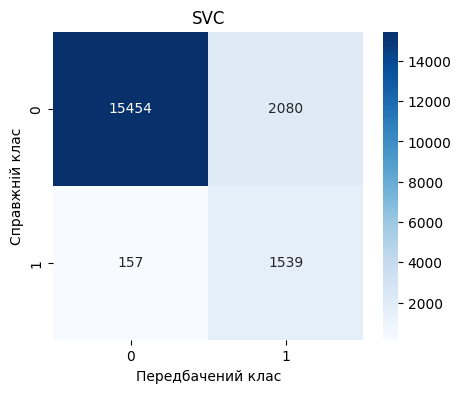

In [112]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "SGD Classifier": SGDClassifier(random_state=42, max_iter=1000),
    "SVC": SVC()
}

model_results = {}

for name, model in models.items():
    print("\n" + "="*60)
    print(name)
    print("="*60)

    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(cm)

    model_results[name] = {
        "model": model,
        "predictions": y_pred,
        "f1": __import__("sklearn.metrics").metrics.f1_score(y_test, y_pred)
    }

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(name)
    plt.xlabel("Передбачений клас")
    plt.ylabel("Справжній клас")
    plt.show()

In [113]:
print("РЕЗУЛЬТАТИ ОПТИМІЗАЦІЇ")
print("="*60)

for name in best_scores:
    print("\nМодель:", name)
    print("Найкращі параметри:", best_models[name].get_params())
    print("Середній F1-score:", best_scores[name])

print("\n" + "="*60)

best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print("НАЙКРАЩА МОДЕЛЬ:", best_model_name)
print("НАЙКРАЩИЙ F1-SCORE:", best_scores[best_model_name])

РЕЗУЛЬТАТИ ОПТИМІЗАЦІЇ

Модель: Logistic Regression
Найкращі параметри: {'memory': None, 'steps': [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('model', LogisticRegression(C=10, max_iter=1000, random_state=42))], 'transform_input': None, 'verbose': False, 'scaler': StandardScaler(), 'smote': SMOTE(random_state=42), 'model': LogisticRegression(C=10, max_iter=1000, random_state=42), 'scaler__copy': True, 'scaler__with_mean': True, 'scaler__with_std': True, 'smote__k_neighbors': 5, 'smote__random_state': 42, 'smote__sampling_strategy': 'auto', 'model__C': 10, 'model__class_weight': None, 'model__dual': False, 'model__fit_intercept': True, 'model__intercept_scaling': 1, 'model__l1_ratio': None, 'model__max_iter': 1000, 'model__multi_class': 'deprecated', 'model__n_jobs': None, 'model__penalty': 'l2', 'model__random_state': 42, 'model__solver': 'lbfgs', 'model__tol': 0.0001, 'model__verbose': 0, 'model__warm_start': False}
Середній F1-score: 0.530594813683049

Модель: R

In [114]:
import numpy as np
import pandas as pd

best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

np.random.seed(42)

random_indices = np.random.choice(
    len(X_test),
    size=10,
    replace=False
)

y_pred_best = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Індекс": random_indices,
    "Істинний клас": np.array(y_test)[random_indices],
    "Передбачений клас": y_pred_best[random_indices]
})

print("ПОРІВНЯННЯ 10 ВИПАДКОВИХ ПРОГНОЗІВ")
display(comparison)

ПОРІВНЯННЯ 10 ВИПАДКОВИХ ПРОГНОЗІВ


,Індекс,Істинний клас,Передбачений клас
0,341,0,0
1,8171,0,0
2,13626,0,1
3,6178,0,0
4,14765,0,0
5,2641,0,0
6,16024,0,0
7,16466,0,0
8,2995,0,1
9,1512,0,0


In [115]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

y_pred_best = best_model.predict(X_test)

print("НАЙКРАЩА МОДЕЛЬ:", best_model_name)
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("F1-score:", f1_score(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

НАЙКРАЩА МОДЕЛЬ: SVC
Accuracy: 0.8827873114924597
F1-score: 0.5714828897338403

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Confusion Matrix:
[[15473  2061]
 [  193  1503]]
